# Assignment 3: SLCM Classification Analysis
**CS-430-01 Machine Learning**

**Prediction question:** Can household and housing information help identify households with \$3,000 or more in past-due rent?

**Note:** For most of the graphs I use AI to help make sure they look clean and easy to read.

## Imports

In [2]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Part 1 – Understand the Classification Problem

## 1. Explore the dataset
- Load the CSV. Display five rows, the data shape, the column names, and missing-value counts.
- Identify one numerical and one categorical feature.
- Answer: Why must `past_due_rent` be excluded from the input features?

In [3]:
CSV_FILE = "SLCM_rent_arrears_student_clean.csv"

if not os.path.exists(CSV_FILE):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Put {CSV_FILE} in the same folder as this notebook.")

df = pd.read_csv(CSV_FILE)
df.head()

Saving SLCM_rent_arrears_student_clean.csv to SLCM_rent_arrears_student_clean.csv


,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


In [4]:
print("Shape (rows, columns):", df.shape)
print()
print("Column names:", list(df.columns))

Shape (rows, columns): (1754, 14)

Column names: ['record_id', 'adults_in_household', 'children_in_household', 'household_has_65plus', 'monthly_household_income', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter', 'monthly_rent', 'past_due_rent']


In [5]:
print("Missing values per column:")
df.isna().sum()

Missing values per column:


,0
record_id,0
adults_in_household,0
children_in_household,0
household_has_65plus,0
monthly_household_income,108
income_sources,0
employment_status,0
has_housing_voucher,0
eviction_in_progress,1
behind_on_utilities,7


**Interpretation:** The data has 1,754 households and 14 columns. Only a few columns have missing values: `monthly_household_income` is missing the most (108 rows), while `monthly_rent`, `behind_on_utilities`, `main_reason_behind_on_rent` and `eviction_in_progress` have only a handful. These will be handled by imputation inside the pipeline.

**One numerical feature:** `monthly_household_income`.  **One categorical feature:** `employment_status`.

**Why exclude `past_due_rent`?** The target `high_arrears` is *defined* from `past_due_rent` (1 if it is at least \$3,000). Using it as an input would hand the model the answer (data leakage): it could score nearly perfectly by learning the \$3,000 cutoff, yet it would be useless for the real goal of identifying high-arrears households from other information.

## 2. Create the target
- Create `high_arrears`: 1 if `past_due_rent` is at least \$3,000, otherwise 0.
- Show class counts and one bar chart of `high_arrears`.
- Answer: Which class is larger? Why might accuracy alone be misleading?

In [6]:
df["high_arrears"] = (df["past_due_rent"] >= 3000).astype(int)

counts = df["high_arrears"].value_counts().sort_index()
print("Class counts:")
print(counts)
print()
print("Class share:")
print((counts / len(df)).round(3))

Class counts:
high_arrears
0    1210
1     544
Name: count, dtype: int64

Class share:
high_arrears
0    0.69
1    0.31
Name: count, dtype: float64


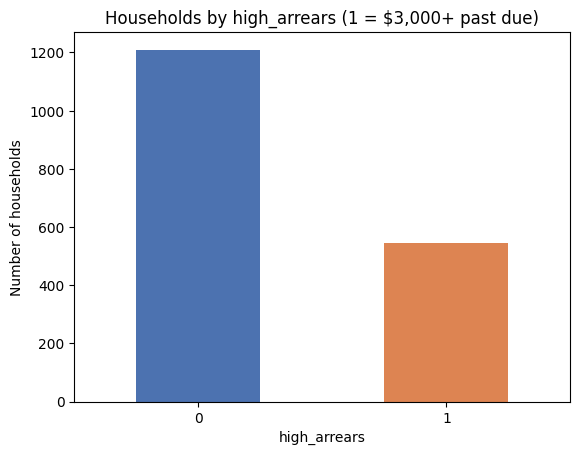

In [7]:
counts.plot(kind="bar", color=["#4C72B0", "#DD8452"])
plt.title("Households by high_arrears (1 = \$3,000+ past due)")
plt.xlabel("high_arrears")
plt.ylabel("Number of households")
plt.xticks(rotation=0)
plt.show()

**Interpretation:** Class 0 (under \$3,000) is larger, with 1,210 households (about 69%) versus 544 (about 31%) in class 1. Accuracy alone can mislead because a model that predicted "not high arrears" for everyone would be right about 69% of the time while finding none of the households SLCM most wants to identify, so recall and F1 for class 1 matter more.

# Part 2 – Prepare the Data

## 3. Select features and split
- Create `X` by dropping `record_id`, `past_due_rent`, and `high_arrears`. Set `y = high_arrears`.
- Split the data once into training and testing sets.
- Answer: Why do we keep a separate test set?

In [8]:
X = df.drop(columns=["record_id", "past_due_rent", "high_arrears"])
y = df["high_arrears"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training:", X_train.shape, " Test:", X_test.shape)
print("Share of class 1 -> train:", round(y_train.mean(), 3), " test:", round(y_test.mean(), 3))

Training: (1403, 12)  Test: (351, 12)
Share of class 1 -> train: 0.31  test: 0.311


**Interpretation:** The split gives 1,403 training and 351 test households, and `stratify=y` keeps the share of high-arrears households almost identical (about 31%) in both. We keep a separate test set so that we can estimate how the model does on households it has never seen; scoring on the training data would reward memorizing it.

## 4. Build one reusable preprocessor
- Identify numerical and categorical columns with `select_dtypes`.
- Numerical: median imputation + `StandardScaler`. Categorical: most_frequent imputation + `OneHotEncoder(handle_unknown="ignore")`.
- Combine with `ColumnTransformer`.
- Answer: Why is scaling helpful for KNN and SVC?

In [9]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

Numerical columns: ['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
Categorical columns: ['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']


**Interpretation:** There are 4 numerical and 8 categorical input columns. The preprocessor is fitted only on whatever data the pipeline is fitted on, so training information never leaks from the test set.

**Why scaling helps KNN and SVC:** Both models rely on distances between households. Without scaling, a column with large values such as `monthly_household_income` or `monthly_rent` (hundreds to thousands) would dominate small-valued columns such as `children_in_household` (0 to a few), so scaling puts all numeric features on a comparable footing.

# Part 3 – Train and Compare Five Models

## 5. Train the five classifiers
Five pipelines with the same preprocessor and the same training set. Accuracy, recall and F1 are reported for class 1.

In [10]:
lr_pipe = Pipeline([("prep", preprocessor), ("model", LogisticRegression(max_iter=1000))])
lr_pipe.fit(X_train, y_train)
lr_pred = lr_pipe.predict(X_test)
print("Logistic Regression -> accuracy:", round(accuracy_score(y_test, lr_pred), 3),
      "recall:", round(recall_score(y_test, lr_pred), 3),
      "F1:", round(f1_score(y_test, lr_pred), 3))

Logistic Regression -> accuracy: 0.695 recall: 0.303 F1: 0.382


In [11]:
knn_pipe = Pipeline([("prep", preprocessor), ("model", KNeighborsClassifier(n_neighbors=5))])
knn_pipe.fit(X_train, y_train)
knn_pred = knn_pipe.predict(X_test)
print("KNN -> accuracy:", round(accuracy_score(y_test, knn_pred), 3),
      "recall:", round(recall_score(y_test, knn_pred), 3),
      "F1:", round(f1_score(y_test, knn_pred), 3))

KNN -> accuracy: 0.681 recall: 0.376 F1: 0.423


In [12]:
dt_pipe = Pipeline([("prep", preprocessor), ("model", DecisionTreeClassifier(max_depth=5, random_state=42))])
dt_pipe.fit(X_train, y_train)
dt_pred = dt_pipe.predict(X_test)
print("Decision Tree -> accuracy:", round(accuracy_score(y_test, dt_pred), 3),
      "recall:", round(recall_score(y_test, dt_pred), 3),
      "F1:", round(f1_score(y_test, dt_pred), 3))

Decision Tree -> accuracy: 0.695 recall: 0.33 F1: 0.402


In [13]:
rf_pipe = Pipeline([("prep", preprocessor), ("model", RandomForestClassifier(n_estimators=100, random_state=42))])
rf_pipe.fit(X_train, y_train)
rf_pred = rf_pipe.predict(X_test)
print("Random Forest -> accuracy:", round(accuracy_score(y_test, rf_pred), 3),
      "recall:", round(recall_score(y_test, rf_pred), 3),
      "F1:", round(f1_score(y_test, rf_pred), 3))

Random Forest -> accuracy: 0.704 recall: 0.321 F1: 0.402


In [14]:
svc_pipe = Pipeline([("prep", preprocessor), ("model", SVC())])
svc_pipe.fit(X_train, y_train)
svc_pred = svc_pipe.predict(X_test)
print("SVC -> accuracy:", round(accuracy_score(y_test, svc_pred), 3),
      "recall:", round(recall_score(y_test, svc_pred), 3),
      "F1:", round(f1_score(y_test, svc_pred), 3))

SVC -> accuracy: 0.707 recall: 0.229 F1: 0.327


**Interpretation:** All five models land in a narrow accuracy band (about 0.68 to 0.71), but recall and F1 for class 1 vary much more. Recall is low for every model, meaning each one misses most high-arrears households.

## 6. Compare the models
- One table with columns Model, Accuracy, Recall, F1.
- One confusion matrix for the model with the highest test F1.
- Answer: Which model catches the highest proportion of high-arrears households? What does a missed case mean for SLCM?

In [15]:
preds = {
    "Logistic Regression": lr_pred,
    "KNN": knn_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "SVC": svc_pred,
}

results = pd.DataFrame({
    "Model": list(preds.keys()),
    "Accuracy": [accuracy_score(y_test, p) for p in preds.values()],
    "Recall": [recall_score(y_test, p) for p in preds.values()],
    "F1": [f1_score(y_test, p) for p in preds.values()],
}).round(3)

results

,Model,Accuracy,Recall,F1
0,Logistic Regression,0.695,0.303,0.382
1,KNN,0.681,0.376,0.423
2,Decision Tree,0.695,0.330,0.402
3,Random Forest,0.704,0.321,0.402
4,SVC,0.707,0.229,0.327


Model with the highest test F1: KNN


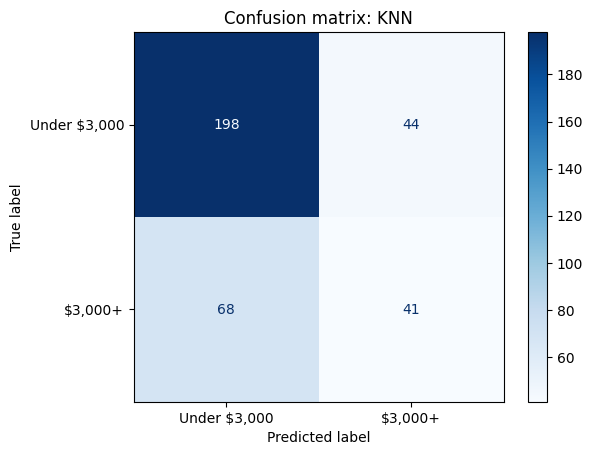

[[198  44]
 [ 68  41]]


In [16]:
best_name = results.loc[results["F1"].idxmax(), "Model"]
print("Model with the highest test F1:", best_name)

ConfusionMatrixDisplay.from_predictions(
    y_test, preds[best_name], display_labels=["Under $3,000", "$3,000+"], cmap="Blues"
)
plt.title(f"Confusion matrix: {best_name}")
plt.show()

print(confusion_matrix(y_test, preds[best_name]))

**Interpretation:** KNN has the highest test F1 (0.423) and also the highest recall (0.376), so it catches the largest share of high-arrears households: 41 of the 109 in the test set. It still missed 68 of them (false negatives) and wrongly flagged 44 households (false positives).

**What a missed case means for SLCM:** A missed household is one with \$3,000 or more in past-due rent that the model labels as lower risk, so it could be overlooked for early outreach or assistance and may get closer to eviction or utility shutoff before help arrives.

## 7. Try a small GridSearchCV
- Tune only KNN and Random Forest on the training set with `cv=3` and `scoring="f1"`.
- KNN: `n_neighbors = [3, 5, 7]`. Random Forest: `max_depth = [3, 5, None]` (keep `n_estimators=100`).
- Print `best_params_` and `best_score_`.
- Answer: Which has the higher best cross-validation F1? Why is GridSearchCV fitted on training data only?

In [17]:
knn_search_pipe = Pipeline([("prep", preprocessor), ("model", KNeighborsClassifier())])
knn_grid = {"model__n_neighbors": [3, 5, 7]}

knn_search = GridSearchCV(knn_search_pipe, knn_grid, cv=3, scoring="f1")
knn_search.fit(X_train, y_train)

print("Best KNN parameters:", knn_search.best_params_)
print("Best KNN CV F1:", round(knn_search.best_score_, 3))

Best KNN parameters: {'model__n_neighbors': 7}
Best KNN CV F1: 0.485


In [18]:
rf_search_pipe = Pipeline([("prep", preprocessor), ("model", RandomForestClassifier(n_estimators=100, random_state=42))])
rf_grid = {"model__max_depth": [3, 5, None]}

rf_search = GridSearchCV(rf_search_pipe, rf_grid, cv=3, scoring="f1")
rf_search.fit(X_train, y_train)

print("Best RF parameters:", rf_search.best_params_)
print("Best RF CV F1:", round(rf_search.best_score_, 3))

Best RF parameters: {'model__max_depth': None}
Best RF CV F1: 0.457


**Interpretation:** KNN has the higher best cross-validation F1 (0.485 with `n_neighbors=7`) compared with Random Forest (0.457 with `max_depth=None`). Both CV scores are higher than the test F1 values above, partly because they come from different data and partly because cross-validation on a small training set is noisy.

**Why fit GridSearchCV on training data only?** The search chooses settings by comparing scores. If it used the test set, the test data would influence the model choice, and the final test score would be too optimistic and no longer a fair estimate for new households. Keeping the test set untouched means it can be used once at the end.

# Part 4 – Explain the Results

## 8. Interpret your comparison
In 4–5 sentences, identify the most promising model based on F1 and recall (not accuracy alone). Did a more complex model necessarily perform better? What types of errors should SLCM pay attention to?

KNN is the most promising model in my results: it had the best test F1 (0.423) and the best recall (0.376), and it also had the best cross-validation F1 in the small grid search (0.485 with 7 neighbors). It does not have the best accuracy (0.681), since SVC (0.707) and Random Forest (0.704) score higher, but SVC had the lowest recall (0.229), which shows that accuracy can hide how many high-arrears households are missed. A more complex model did not necessarily do better: Random Forest and SVC were not better than the simple KNN and Logistic Regression models on the measures that matter here, and the differences between models are small on a test set with only 109 high-arrears households. SLCM should pay most attention to false negatives (households with \$3,000+ in arrears that the model misses), while false positives mainly cost some extra staff time. Overall, even the best model misses most of the high-arrears households, so it is only a weak screening aid.

## 9. Recommendation to SLCM
Write 4–5 sentences for a non-technical SLCM audience: what you tried to predict, how well the selected model performed, one practical insight, and one limitation. State that a prediction is not proof of cause and must not be used alone to decide eligibility for assistance.

We tried to predict which households have \$3,000 or more in past-due rent using household and housing information from intake. The model we selected (a nearest-neighbors model) found about 4 in 10 of the high-arrears households in our test group (recall of 0.38), and about half of the households it flagged (41 of 85) really were high-arrears, so it is better than guessing but far from precise. One practical insight is that accuracy looks fine (about 68 to 71%) for every model because most households are below \$3,000, so SLCM should judge any tool by how many high-need households it actually finds. One limitation is that the model misses most high-arrears households and was trained on one set of intake records, so it may not hold up for new households or time periods. A prediction is not proof of cause, and it must not be used alone to decide eligibility for assistance; staff judgment and each household's circumstances must come first.